In [104]:
import pandas as pd
from pathlib import Path

from sentence_transformers import SentenceTransformer

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report

In [105]:
current_dir = Path().cwd()
print(current_dir)

/home/hamza/serious_stuff/adaptive-llm-router/notebooks


In [106]:
root_project = current_dir.parent
print(root_project)

/home/hamza/serious_stuff/adaptive-llm-router


In [107]:
data_file = root_project / "data" / "raw" / "prompt_classifier_dataset_1000.jsonl"

new_data_file = root_project / "data" / "prompt_classifier_dataset_v2_2000.jsonl"


print(data_file)
print(new_data_file)

/home/hamza/serious_stuff/adaptive-llm-router/data/raw/prompt_classifier_dataset_1000.jsonl
/home/hamza/serious_stuff/adaptive-llm-router/data/prompt_classifier_dataset_v2_2000.jsonl


In [108]:
df = pd.read_json(data_file, lines=True)
new_df = pd.read_json(new_data_file, lines=True)


In [109]:
print(df.columns)
print(new_df.columns)

Index(['id', 'prompt', 'task_type', 'difficulty', 'difficulty_bucket',
       'required_quality', 'risk_level', 'expected_output_tokens',
       'latency_sensitivity'],
      dtype='str')
Index(['id', 'prompt', 'task_type', 'difficulty', 'difficulty_bucket',
       'required_quality', 'risk_level', 'expected_output_tokens',
       'latency_sensitivity'],
      dtype='str')


In [110]:
print(df.isnull().sum())
print(df.duplicated().sum())

print(new_df.isnull().sum())
print(new_df.duplicated().sum())

id                        0
prompt                    0
task_type                 0
difficulty                0
difficulty_bucket         0
required_quality          0
risk_level                0
expected_output_tokens    0
latency_sensitivity       0
dtype: int64
0
id                        0
prompt                    0
task_type                 0
difficulty                0
difficulty_bucket         0
required_quality          0
risk_level                0
expected_output_tokens    0
latency_sensitivity       0
dtype: int64
0


In [111]:
print(df.iloc[0])

id                                                              pc_0001
prompt                    Compare RabbitMQ and RabbitMQ with tradeoffs.
task_type                                                     reasoning
difficulty                                                        0.651
difficulty_bucket                                                medium
required_quality                                                  0.872
risk_level                                                         high
expected_output_tokens                                              933
latency_sensitivity                                              medium
Name: 0, dtype: object


In [112]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id                      1000 non-null   str    
 1   prompt                  1000 non-null   str    
 2   task_type               1000 non-null   str    
 3   difficulty              1000 non-null   float64
 4   difficulty_bucket       1000 non-null   str    
 5   required_quality        1000 non-null   float64
 6   risk_level              1000 non-null   str    
 7   expected_output_tokens  1000 non-null   int64  
 8   latency_sensitivity     1000 non-null   str    
dtypes: float64(2), int64(1), str(6)
memory usage: 70.4 KB
None


In [113]:
print(df.describe())

        difficulty  required_quality  expected_output_tokens
count  1000.000000       1000.000000             1000.000000
mean      0.503597          0.808187              624.528000
std       0.221934          0.123518              284.913139
min       0.050000          0.560000               95.000000
25%       0.319750          0.732000              405.000000
50%       0.494000          0.808000              554.500000
75%       0.686000          0.923000              832.500000
max       0.980000          0.970000             1351.000000


In [114]:
x = new_df["prompt"]
y = new_df["task_type"]



In [115]:
print(x[0:5])
x_list = list(x)
print(x_list[0:5])

0    What is causing this discrepancy? Point to the...
1    Identify the causal claim and test it against ...
2    I am working through the following. At our reg...
3    Use established terminology, with a brief exam...
4    This is for an interactive assistant; please r...
Name: prompt, dtype: str
["What is causing this discrepancy? Point to the faulty operation and give the smallest correction consistent with the stated behaviour. Keep the explanation under 120 words, plus any patch.\nFor context, Python example:\nimport re\ndef valid(s): return bool(re.match(r'[0-9]+', s))\nObserved behaviour: valid('12x') returns True; the whole nonempty string must contain only ASCII digits. This is a reproducible local exercise with disposable data.", 'Identify the causal claim and test it against two alternative explanations grounded in this account. What observation would discriminate between them?\nFor context, Case for an analytical exercise: An apartment office closes repair tickets faster a

In [116]:
embedding_model = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')
embeddings = embedding_model.encode(x_list)


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 9079.15it/s]


In [117]:
print(type(embeddings))
print(embeddings.shape)

<class 'numpy.ndarray'>
(2000, 384)


In [118]:
X = embeddings
y = new_df["task_type"]

In [119]:
print(y.unique())

<StringArray>
[    'debugging',     'reasoning',       'writing',       'factual',
 'summarization',      'creative', 'system_design',          'math',
    'extraction',        'coding']
Length: 10, dtype: str


In [131]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [137]:
model = LogisticRegression(max_iter=10000)
model.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",10000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use 

In [138]:
y_pred = model.predict(X_test)


In [139]:

acc = accuracy_score(y_true=y_test, y_pred=y_pred) * 100
precision = precision_score(y_true=y_test, y_pred=y_pred, average="weighted", zero_division=0) * 100
recall = recall_score(y_true=y_test, y_pred=y_pred, average="weighted", zero_division=0) * 100
f1 = f1_score(y_true=y_test, y_pred=y_pred, average="weighted", zero_division=0) * 100

print(f"Logistic Regression Accuracy:  {acc:.2f}%")
print(f"Logistic Regression Precision: {precision:.2f}%")
print(f"Logistic Regression Recall:    {recall:.2f}%")
print(f"Logistic Regression F1-score:  {f1:.2f}%")

Logistic Regression Accuracy:  99.75%
Logistic Regression Precision: 99.76%
Logistic Regression Recall:    99.75%
Logistic Regression F1-score:  99.75%


In [140]:
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

               precision    recall  f1-score   support

       coding       1.00      1.00      1.00        40
     creative       1.00      1.00      1.00        40
    debugging       1.00      1.00      1.00        40
   extraction       1.00      1.00      1.00        40
      factual       0.98      1.00      0.99        40
         math       1.00      1.00      1.00        40
    reasoning       1.00      0.97      0.99        40
summarization       1.00      1.00      1.00        40
system_design       1.00      1.00      1.00        40
      writing       1.00      1.00      1.00        40

     accuracy                           1.00       400
    macro avg       1.00      1.00      1.00       400
 weighted avg       1.00      1.00      1.00       400



In [141]:
print(new_df[
    new_df["task_type"] == "coding"
])

              id                                             prompt task_type  \
30    pc_v2_0031  This is for an interactive assistant; please r...    coding   
39    pc_v2_0040  Build a reusable Python module for this contra...    coding   
40    pc_v2_0041  Provide a typed TypeScript implementation and ...    coding   
42    pc_v2_0043  This is for an interactive assistant; please r...    coding   
50    pc_v2_0051  The behaviour we need is to turn a sequence of...    coding   
...          ...                                                ...       ...   
1972  pc_v2_1973  The behaviour we need is to count directed inc...    coding   
1984  pc_v2_1985  The behaviour we need is to flatten nested lis...    coding   
1985  pc_v2_1986  A person is waiting on this chat for the resul...    coding   
1986  pc_v2_1987  This is for an interactive assistant; please r...    coding   
1991  pc_v2_1992  The behaviour we need is to flatten nested lis...    coding   

      difficulty difficulty

In [142]:
print(y[0:5])

0    debugging
1    reasoning
2      writing
3      factual
4    debugging
Name: task_type, dtype: str


In [145]:
sample = df.sample(n=30)
print(sample.shape)

(30, 9)


In [76]:
sample.to_json(root_project / "data" / "raw" / "30_examples.jsonl")

In [130]:
print(new_df.duplicated().sum())
print("Doublons V1 :", df["prompt"].duplicated().sum())
print("Doublons V2 :", new_df["prompt"].duplicated().sum())

common_prompts = set(df["prompt"]) & set(new_df["prompt"])

print("Prompts communs V1/V2 :", len(common_prompts))

0
Doublons V1 : 394
Doublons V2 : 0
Prompts communs V1/V2 : 0


In [161]:


embedding_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)

# Embeddings V1
X_v1 = embedding_model.encode(
    df["prompt"].tolist()
)

y_v1 = df["task_type"]

# Embeddings V2
X_v2 = embedding_model.encode(
    new_df["prompt"].tolist()
)

y_v2 = new_df["task_type"]

# Entraîner uniquement sur V1
model_v1 = LogisticRegression(max_iter=1000)
model_v1.fit(X_v1, y_v1)

# Évaluer sur V2
y_pred_v2 = model_v1.predict(X_v2)

print("Accuracy V1 -> V2 :")
print(accuracy_score(y_v2, y_pred_v2))

print("\nClassification Report :")
print(classification_report(y_v2, y_pred_v2))

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 7250.98it/s]


Accuracy V1 -> V2 :
0.6305

Classification Report :
               precision    recall  f1-score   support

       coding       0.89      0.94      0.91       200
     creative       0.89      0.32      0.47       200
    debugging       0.99      0.78      0.87       200
   extraction       0.96      0.46      0.62       200
      factual       0.85      0.82      0.84       200
         math       0.50      0.92      0.65       200
    reasoning       0.55      0.29      0.38       200
summarization       0.40      0.55      0.46       200
system_design       1.00      0.25      0.40       200
      writing       0.41      0.98      0.58       200

     accuracy                           0.63      2000
    macro avg       0.75      0.63      0.62      2000
 weighted avg       0.75      0.63      0.62      2000



Accuracy V2 -> V1 : 49.60%

Classification Report :
               precision    recall  f1-score   support

       coding       0.78      0.36      0.50       129
     creative       0.41      0.17      0.25        40
    debugging       0.93      0.78      0.85        83
   extraction       0.75      0.74      0.74       100
      factual       0.30      0.78      0.43        93
         math       0.43      0.68      0.53        77
    reasoning       0.40      0.10      0.16       119
summarization       0.54      0.11      0.19       115
system_design       0.37      0.87      0.52       106
      writing       0.69      0.44      0.54       138

     accuracy                           0.50      1000
    macro avg       0.56      0.50      0.47      1000
 weighted avg       0.58      0.50      0.47      1000



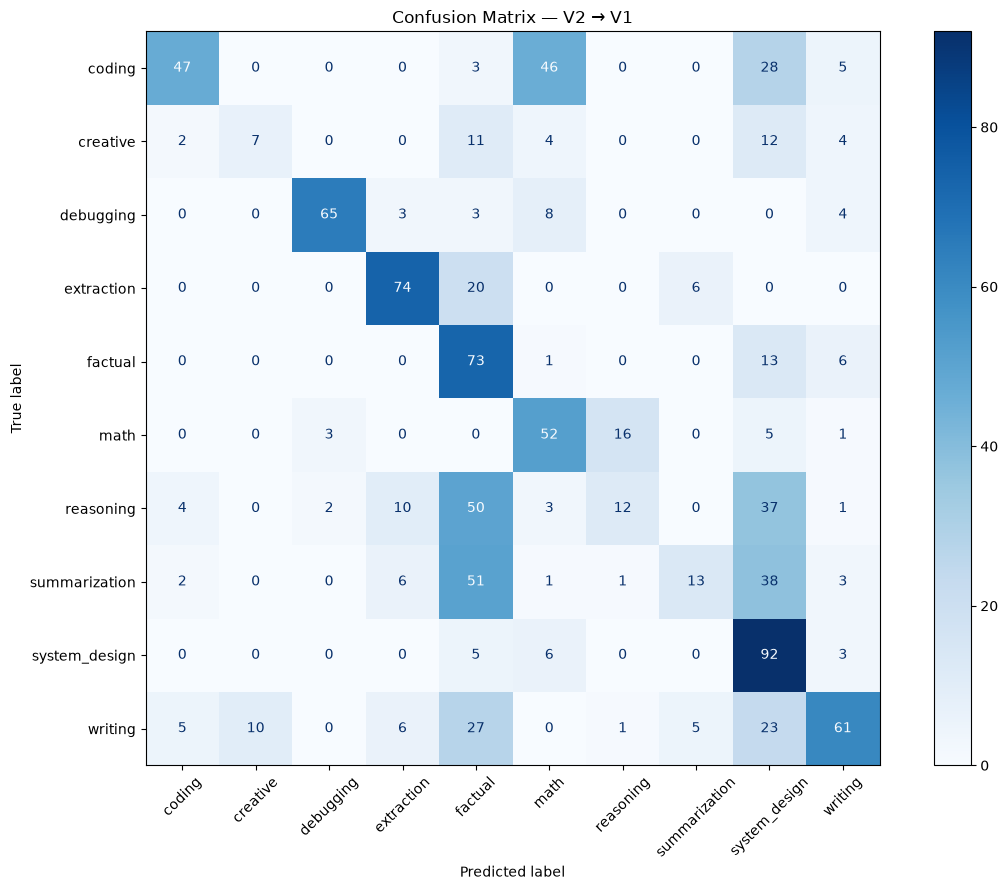

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

# Entraîner sur V2 (2 000 exemples)
model_v2 = LogisticRegression(max_iter=1000)
model_v2.fit(X_v2, y_v2)

# Tester sur V1 (1 000 exemples)
y_pred_v1 = model_v2.predict(X_v1)

# Évaluation
accuracy = accuracy_score(y_v1, y_pred_v1)

print(f"Accuracy V2 -> V1 : {accuracy:.2%}")

print("\nClassification Report :")
print(classification_report(
    y_v1,
    y_pred_v1,
    zero_division=0
))

# Matrice de confusion
fig, ax = plt.subplots(figsize=(12, 9))

ConfusionMatrixDisplay.from_predictions(
    y_v1,
    y_pred_v1,
    cmap="Blues",
    xticks_rotation=45,
    ax=ax
)

plt.title("Confusion Matrix — V2 → V1")
plt.tight_layout()
plt.show()

In [148]:
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

# Découpage indépendant de chaque dataset

X_v1_train, X_v1_test, y_v1_train, y_v1_test = train_test_split(
    X_v1,
    y_v1,
    test_size=0.2,
    random_state=42,
    stratify=y_v1
)

X_v2_train, X_v2_test, y_v2_train, y_v2_test = train_test_split(
    X_v2,
    y_v2,
    test_size=0.2,
    random_state=42,
    stratify=y_v2
)

# Fusion des données d'entraînement uniquement

X_train_combined = np.vstack([
    X_v1_train,
    X_v2_train
])

y_train_combined = np.concatenate([
    np.asarray(y_v1_train),
    np.asarray(y_v2_train)
])

# Entraînement

model_combined = LogisticRegression(max_iter=1000)

model_combined.fit(
    X_train_combined,
    y_train_combined
)

# Évaluation séparée

for dataset_name, X_test, y_test in [
    ("V1", X_v1_test, y_v1_test),
    ("V2", X_v2_test, y_v2_test)
]:

    predictions = model_combined.predict(X_test)

    print(f"\n===== TEST {dataset_name} =====")

    print(
        "Accuracy:",
        accuracy_score(y_test, predictions)
    )

    print(
        classification_report(
            y_test,
            predictions,
            zero_division=0
        )
    )


===== TEST V1 =====
Accuracy: 0.96
               precision    recall  f1-score   support

       coding       1.00      1.00      1.00        26
     creative       1.00      1.00      1.00         8
    debugging       1.00      0.94      0.97        16
   extraction       1.00      1.00      1.00        20
      factual       0.95      1.00      0.97        19
         math       1.00      0.87      0.93        15
    reasoning       0.84      0.88      0.86        24
summarization       1.00      0.91      0.95        23
system_design       0.91      1.00      0.95        21
      writing       0.97      1.00      0.98        28

     accuracy                           0.96       200
    macro avg       0.97      0.96      0.96       200
 weighted avg       0.96      0.96      0.96       200


===== TEST V2 =====
Accuracy: 0.9925
               precision    recall  f1-score   support

       coding       1.00      1.00      1.00        40
     creative       1.00      1.00      1.

In [149]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(
    n_neighbors=5,
    metric="cosine",
    weights="distance"
)

knn.fit(X_train_combined, y_train_combined)

,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'distance'
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'cosine'
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](10,)","['coding','creative','debugging',...,'summarization','system_design', 'writing']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'cosine'


In [150]:
from sklearn.metrics import accuracy_score, classification_report

for dataset_name, X_test, y_test in [
    ("V1", X_v1_test, y_v1_test),
    ("V2", X_v2_test, y_v2_test)
]:

    y_pred = knn.predict(X_test)

    print(f"\n===== KNN — TEST {dataset_name} =====")

    print(f"Accuracy: {accuracy_score(y_test, y_pred):.2%}")

    print(classification_report(
        y_test,
        y_pred,
        zero_division=0
    ))


===== KNN — TEST V1 =====
Accuracy: 80.00%
               precision    recall  f1-score   support

       coding       1.00      0.92      0.96        26
     creative       1.00      0.50      0.67         8
    debugging       1.00      1.00      1.00        16
   extraction       1.00      1.00      1.00        20
      factual       0.46      0.58      0.51        19
         math       0.90      0.60      0.72        15
    reasoning       0.83      0.62      0.71        24
summarization       0.57      0.70      0.63        23
system_design       0.81      1.00      0.89        21
      writing       0.80      0.86      0.83        28

     accuracy                           0.80       200
    macro avg       0.84      0.78      0.79       200
 weighted avg       0.82      0.80      0.80       200


===== KNN — TEST V2 =====
Accuracy: 97.00%
               precision    recall  f1-score   support

       coding       0.95      1.00      0.98        40
     creative       1.00    

In [151]:
import pandas as pd

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.neighbors import KNeighborsClassifier

k_values = [1, 3, 5, 7, 11, 15, 21]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for k in k_values:

    model = KNeighborsClassifier(
        n_neighbors=k,
        metric="cosine",
        weights="distance"
    )

    scores = cross_validate(
        model,
        X_train_combined,
        y_train_combined,
        cv=cv,
        scoring="f1_macro",
        n_jobs=-1
    )

    results.append({
        "k": k,
        "macro_f1": scores["test_score"].mean(),
        "std": scores["test_score"].std()
    })

results_df = pd.DataFrame(results)

display(results_df.sort_values("macro_f1", ascending=False))

,k,macro_f1,std
0,1,0.922138,0.006104
1,3,0.916951,0.010141
6,21,0.916912,0.006189
2,5,0.912659,0.006897
3,7,0.912049,0.007683
5,15,0.911867,0.011875
4,11,0.908932,0.008585


In [152]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score

knn_1 = KNeighborsClassifier(
    n_neighbors=1,
    metric="cosine"
)

knn_1.fit(X_train_combined, y_train_combined)

for name, X_test, y_test in [
    ("V1", X_v1_test, y_v1_test),
    ("V2", X_v2_test, y_v2_test)
]:
    predictions = knn_1.predict(X_test)

    print(f"\n{name}")
    print(f"Accuracy: {accuracy_score(y_test, predictions):.2%}")
    print(f"Macro F1: {f1_score(y_test, predictions, average='macro'):.2%}")


V1
Accuracy: 82.00%
Macro F1: 81.67%

V2
Accuracy: 96.00%
Macro F1: 95.91%


In [153]:
import pandas as pd

# Fusionner les datasets
df_combined = pd.concat(
    [df, new_df],
    ignore_index=True
)

# Mélanger les lignes
df_combined = df_combined.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("Nombre de prompts :", len(df_combined))
print(df_combined["task_type"].value_counts())

Nombre de prompts : 3000
task_type
writing          338
coding           329
reasoning        319
summarization    315
system_design    306
extraction       300
factual          293
debugging        283
math             277
creative         240
Name: count, dtype: int64


In [154]:
# Normaliser les prompts pour détecter les doublons
df_combined["normalized_prompt"] = (
    df_combined["prompt"]
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
)

print(
    "Doublons :",
    df_combined["normalized_prompt"].duplicated().sum()
)

# Vérifier les labels contradictoires
conflicts = (
    df_combined.groupby("normalized_prompt")["task_type"]
    .nunique()
)

print(
    "Prompts avec labels contradictoires :",
    (conflicts > 1).sum()
)

Doublons : 394
Prompts avec labels contradictoires : 0


In [155]:
df_combined = df_combined.drop_duplicates(
    subset="normalized_prompt"
).reset_index(drop=True)

print("Nombre de prompts uniques :", len(df_combined))

Nombre de prompts uniques : 2606


In [156]:
from sentence_transformers import SentenceTransformer

embedding_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)

prompts = df_combined["prompt"].tolist()

X = embedding_model.encode(
    prompts,
    show_progress_bar=True
)

y = df_combined["task_type"].to_numpy()

print("X :", X.shape)
print("y :", y.shape)

Batches: 100%|██████████| 82/82 [00:02<00:00, 40.69it/s]

X : (2606, 384)
y : (2606,)


In [157]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training :", X_train.shape)
print("Testing :", X_test.shape)

Training : (2084, 384)
Testing : (522, 384)


In [158]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [159]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print(f"Accuracy: {accuracy_score(y_test, y_pred):.2%}")

print(
    f"Precision: "
    f"{precision_score(y_test, y_pred, average='macro', zero_division=0):.2%}"
)

print(
    f"Recall: "
    f"{recall_score(y_test, y_pred, average='macro', zero_division=0):.2%}"
)

print(
    f"F1-score: "
    f"{f1_score(y_test, y_pred, average='macro', zero_division=0):.2%}"
)

print("\nClassification Report :")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 96.74%
Precision: 96.87%
Recall: 96.77%
F1-score: 96.78%

Classification Report :
               precision    recall  f1-score   support

       coding       1.00      0.96      0.98        57
     creative       0.98      0.98      0.98        46
    debugging       0.98      1.00      0.99        50
   extraction       0.98      1.00      0.99        47
      factual       0.96      0.96      0.96        54
         math       1.00      0.94      0.97        49
    reasoning       0.96      0.91      0.93        53
summarization       0.92      0.96      0.94        51
system_design       0.92      1.00      0.96        57
      writing       0.98      0.97      0.97        58

     accuracy                           0.97       522
    macro avg       0.97      0.97      0.97       522
 weighted avg       0.97      0.97      0.97       522



In [160]:
from pathlib import Path

# Dossier de destination
data_dir = root_project / "data" / "raw"

# Créer le dossier s'il n'existe pas
data_dir.mkdir(parents=True, exist_ok=True)

# Chemins des fichiers
jsonl_path = data_dir / "prompt_classifier_dataset_merged.jsonl"
csv_path = data_dir / "prompt_classifier_dataset_merged.csv"

# Supprimer la colonne temporaire de normalisation si elle existe
df_to_save = df_combined.drop(
    columns=["normalized_prompt"],
    errors="ignore"
)

# Sauvegarder en JSONL
df_to_save.to_json(
    jsonl_path,
    orient="records",
    lines=True,
    force_ascii=False
)

# Sauvegarder en CSV
df_to_save.to_csv(
    csv_path,
    index=False
)

print(f"Dataset sauvegardé : {len(df_to_save)} prompts")
print(f"JSONL : {jsonl_path}")
print(f"CSV   : {csv_path}")

Dataset sauvegardé : 2606 prompts
JSONL : /home/hamza/serious_stuff/adaptive-llm-router/data/raw/prompt_classifier_dataset_merged.jsonl
CSV   : /home/hamza/serious_stuff/adaptive-llm-router/data/raw/prompt_classifier_dataset_merged.csv
